# Práctica 1 — Aprendizaje no supervisado: la paleta de los pintores

**Machine Learning · Máster Universitario en Inteligencia Artificial · curso 2026/2027**

Grupo: *4* · Integrantes: *Carlos Chapman Peña*, *Miguel Ángel Gordillo Masero*, *María Xiaolan Ríos Díaz*, *Pablo Sola Díaz*

---

Este es el cuaderno **de partida**. Contiene la información del entorno, las rutas de los datos de
**vuestro grupo** (cada grupo tiene sus propios cuadros), las funciones que la práctica
proporciona, la comprobación del sello y el esqueleto de secciones en el orden en que debéis
trabajar. **Todo lo marcado `TODO` es vuestro**, en código y en Markdown.

Leed el enunciado antes de empezar. Tres reglas deciden buena parte de la nota:

1. **La interpretación va en celdas Markdown**, no en comentarios de Python.
2. **El sello no supervisado cubre los Ejercicios 3 y 4.** El orden de abajo no se negocia y se
   evalúa: los metadatos (autor, época, título...) no se tocan hasta la revelación.
3. **En el Ejercicio 1 diseñáis y programáis vuestra propia variante de $K$-means** como estimador
   de scikit-learn, y la volvéis a usar en el Ejercicio 3.

## 0. Entorno y constantes fijadas por el curso

Ejecutad esto primero. Imprime las versiones con las que se obtuvieron los resultados, las tres
semillas del curso y vuestro número de grupo. **No cambiéis `P1_SEEDS`, `K_DIC` ni
`PIX_POR_CUADRO`**; `GRUPO` y `CUADROS_EJ1` se leen de `Datos/grupo.json`.

In [5]:
# --- Práctica 1: entorno y constantes fijadas por el curso ------------------
import os, platform, json, re
import numpy as np, pandas as pd, matplotlib, sklearn, scipy
import matplotlib.pyplot as plt
from PIL import Image

P1_SEEDS = [13, 41, 97]        # las tres semillas fijadas por el curso: no se cambian
SEED = P1_SEEDS[0]             # la semilla única, donde haga falta una

DATOS = os.path.join("..", "Datos")            # carpeta de datos de vuestro grupo, relativa a este cuaderno
CUADROS_FILE = os.path.join(DATOS, "cuadros.csv")
CUADROS_DIR = os.path.join(DATOS, "cuadros")
# La ruta de los metadatos (autor, época...) NO se define aquí a propósito:
# es una constante de la etapa de revelación.

with open(os.path.join(DATOS, "grupo.json"), encoding="utf-8") as f:
    _grupo = json.load(f)
GRUPO = _grupo["grupo"]                   # cada grupo tiene su propio conjunto de cuadros
CUADROS_EJ1 = _grupo["CUADROS_EJ1"]       # row_id de los tres cuadros del Ejercicio 1
K_DIC = 24                     # tamaño del diccionario común de colores (Ejercicio 2)
PIX_POR_CUADRO = 2000          # píxeles de cada cuadro para ajustar el diccionario

print("python      ", platform.python_version())
print("numpy       ", np.__version__)
print("scipy       ", scipy.__version__)
print("scikit-learn", sklearn.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", matplotlib.__version__)
print("Pillow      ", Image.__version__)
print("P1_SEEDS    ", P1_SEEDS)
print("GRUPO       ", GRUPO, f"({_grupo['n_cuadros']} cuadros)")


python       3.12.10
numpy        1.26.4
scipy        1.15.3
scikit-learn 1.6.1
pandas       2.2.3
matplotlib   3.10.3
Pillow       11.2.1
P1_SEEDS     [13, 41, 97]
GRUPO        4 (56 cuadros)


Las funciones siguientes están **proporcionadas**: cargan los datos, comprueban un estimador y
dibujan paletas, rejillas de miniaturas, dendrogramas y mapas. Ninguna de ellas lee metadatos.

In [6]:
# --- PROPORCIONADO. No modifiquéis estas funciones. --------------------------
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from scipy.cluster.hierarchy import dendrogram


def cargar_cuadros(path=CUADROS_FILE):
    """Tabla de cuadros: row_id, fichero, ancho, alto. No contiene autor ni ningún metadato."""
    tab = pd.read_csv(path)
    assert list(tab.columns) == ["row_id", "fichero", "ancho", "alto"], list(tab.columns)
    return tab


def cargar_imagen(fichero):
    """Devuelve el cuadro como array uint8 de forma (alto, ancho, 3)."""
    return np.asarray(Image.open(os.path.join(CUADROS_DIR, fichero)).convert("RGB"))


def a_pixeles(img):
    """Imagen (alto, ancho, 3) en uint8 -> matriz (número de píxeles, 3) en [0, 1]."""
    return img.reshape(-1, 3).astype(float) / 255.0


def mostrar_paleta(ax, colores, proporciones):
    """Tira horizontal con los colores ordenados de mayor a menor proporción."""
    colores, proporciones = np.asarray(colores), np.asarray(proporciones, float)
    orden = np.argsort(-proporciones)
    izq = 0.0
    for c, p in zip(colores[orden], proporciones[orden] / proporciones.sum()):
        ax.barh(0, p, left=izq, color=np.clip(c, 0, 1), height=1.0)
        izq += p
    ax.set_xlim(0, 1); ax.set_ylim(-0.5, 0.5); ax.axis("off")


def rand_ajustado(a, b):
    """Índice de Rand ajustado entre DOS PARTICIONES vuestras (Tema 2), calculado a partir de la
    tabla de contingencia. Sirve para comparar particiones entre sí en los Ejercicios 1-4; la
    función equivalente de scikit-learn queda reservada a la revelación (el sello la vigila)."""
    _, ia = np.unique(a, return_inverse=True); _, ib = np.unique(b, return_inverse=True)
    T = np.zeros((ia.max() + 1, ib.max() + 1)); np.add.at(T, (ia, ib), 1)
    c2 = lambda x: x * (x - 1) / 2
    s, sa, sb, N = c2(T).sum(), c2(T.sum(1)).sum(), c2(T.sum(0)).sum(), c2(len(a))
    esperado = sa * sb / N
    return float((s - esperado) / (0.5 * (sa + sb) - esperado))


def comprobar_estimador(est, X):
    """Comprobaciones mínimas de que `est` es un estimador de agrupamiento de scikit-learn.
    No sustituye a sklearn.utils.estimator_checks.check_estimator, que podéis investigar."""
    from sklearn.base import BaseEstimator, ClusterMixin, clone
    X = np.asarray(X, dtype=float)
    res = []
    def ok(nombre, cond):
        res.append((nombre, bool(cond)))
    ok("hereda de BaseEstimator", isinstance(est, BaseEstimator))
    ok("hereda de ClusterMixin", isinstance(est, ClusterMixin))
    ok("clone() conserva los parámetros", clone(est).get_params() == est.get_params())
    e1 = clone(est)
    ok("fit devuelve el propio estimador", e1.fit(X) is e1)
    ok("labels_ con una etiqueta por patrón", hasattr(e1, "labels_") and np.shape(e1.labels_) == (len(X),))
    ok("n_iter_ existe", hasattr(e1, "n_iter_"))
    ok("fit_predict coincide con labels_ de fit",
       np.array_equal(clone(est).fit_predict(X), e1.labels_))
    if hasattr(e1, "predict"):
        ok("predict sobre los datos de ajuste reproduce labels_", np.array_equal(e1.predict(X), e1.labels_))
    ok("dos ajustes con los mismos parámetros dan lo mismo", np.array_equal(clone(est).fit(X).labels_, e1.labels_))
    for nombre, c in res:
        print(f"  [{'OK' if c else 'FALLA'}] {nombre}")
    print("TODO CORRECTO" if all(c for _, c in res) else "HAY COMPROBACIONES QUE FALLAN")
    return all(c for _, c in res)


_MINI = {}
def _miniatura(fichero, lado):
    clave = (fichero, lado)
    if clave not in _MINI:
        im = Image.open(os.path.join(CUADROS_DIR, fichero)).convert("RGB")
        im.thumbnail((lado, lado))
        _MINI[clave] = np.asarray(im)
    return _MINI[clave]


def rejilla_miniaturas(ficheros, grupos, titulo=None, lado=70, rotulos=None):
    """Una fila por grupo, con las miniaturas de sus cuadros.
    rotulos (opcional): un texto por cuadro, que se escribe encima de su miniatura."""
    ficheros, grupos = list(ficheros), np.asarray(grupos)
    ids = sorted(set(grupos.tolist()))
    cols = max(int((grupos == g).sum()) for g in ids)
    fig, axs = plt.subplots(len(ids), cols + 1, figsize=((cols + 1) * 0.95, len(ids) * 1.15), squeeze=False)
    for r, g in enumerate(ids):
        idx = np.where(grupos == g)[0]
        axs[r, 0].axis("off")
        axs[r, 0].text(0.95, 0.5, f"grupo {g}\n({len(idx)})", ha="right", va="center", fontsize=8,
                       transform=axs[r, 0].transAxes)
        for j in range(cols):
            a = axs[r, j + 1]; a.axis("off")
            if j < len(idx):
                a.imshow(_miniatura(ficheros[idx[j]], lado))
                if rotulos is not None:
                    a.set_title(str(rotulos[idx[j]]), fontsize=6)
    if titulo:
        fig.suptitle(titulo, fontsize=10)
    fig.tight_layout()
    plt.show()


def dendrograma_con_miniaturas(Z, ficheros, K=None, titulo=None, lado=40):
    """Dendrograma de la matriz de enlace Z (scipy) con las miniaturas bajo las hojas.
    Si se da K, dibuja la línea de corte que deja exactamente K grupos."""
    ficheros = list(ficheros); n = len(ficheros)
    fig, ax = plt.subplots(figsize=(max(12, 0.3 * n), 5.5))
    dn = dendrogram(Z, ax=ax, no_labels=True, color_threshold=0, above_threshold_color="#1f3b73")
    for x, hoja in zip(np.arange(5, 10 * n, 10), dn["leaves"]):
        ab = AnnotationBbox(OffsetImage(_miniatura(ficheros[hoja], lado), zoom=0.5), (x, 0),
                            xybox=(0, -16), xycoords="data", boxcoords="offset points",
                            frameon=False, annotation_clip=False)
        ax.add_artist(ab)
    if K is not None and 1 < K <= n:
        h = Z[:, 2]
        ax.axhline((h[n - K - 1] + h[n - K]) / 2, color="#c0392b", ls="--", lw=1)
        ax.text(ax.get_xlim()[1], (h[n - K - 1] + h[n - K]) / 2, f"  K = {K}", va="center",
                color="#c0392b", fontsize=9)
    ax.set_ylabel("altura de fusión")
    if titulo:
        ax.set_title(titulo)
    fig.subplots_adjust(bottom=0.16)
    plt.show()


def mapa_con_miniaturas(S, ficheros, titulo=None, etiquetas_ejes=("CP1", "CP2"), lado=46,
                        colores_marco=None):
    """Diagrama de dispersión de las dos columnas de S con la miniatura de cada cuadro.
    colores_marco (opcional): un color por cuadro para el marco de su miniatura."""
    S = np.asarray(S)[:, :2]
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.scatter(S[:, 0], S[:, 1], s=2, color="0.6")
    for i, ((a, b), f) in enumerate(zip(S, ficheros)):
        props = dict(edgecolor=colores_marco[i], lw=2) if colores_marco is not None else None
        ab = AnnotationBbox(OffsetImage(_miniatura(f, lado), zoom=0.75), (a, b),
                            frameon=colores_marco is not None, bboxprops=props, pad=0.1)
        ax.add_artist(ab)
    ax.set_xlabel(etiquetas_ejes[0]); ax.set_ylabel(etiquetas_ejes[1])
    if titulo:
        ax.set_title(titulo)
    plt.show()

### La comprobación del sello

Esta función lee el JSON del propio cuaderno y comprueba tres cosas: que los dos encabezados de
congelación existen **exactamente una vez cada uno**, que la congelación de $K$-means va primero,
y que el primer acceso **ejecutable** a los metadatos (autor, técnica...) ocurre estrictamente
después de la segunda congelación. Ejecutadla al final, sobre el fichero guardado, antes de
entregar.

In [7]:
# --- El sello no supervisado, comprobado de forma automática ----------------
# Lee el JSON del cuaderno y comprueba:
#   1. los dos encabezados de congelación existen, exactamente una vez cada uno;
#   2. la congelación de K-means precede a la del aglomerativo;
#   3. el primer acceso EJECUTABLE a los metadatos ocurre después de la segunda.
# Solo cuentan como congelación los ENCABEZADOS Markdown, y solo las celdas de CÓDIGO
# cuentan como acceso: el sello trata de lo que se ejecutó, no de lo que se escribió.
CONGELA_KM = "DECISIÓN CONGELADA — K-MEANS"
CONGELA_AG = "DECISIÓN CONGELADA — AGLOMERATIVO"

# todas las vías ejecutables hacia los metadatos
PATRON_META = re.compile(
    r"METADATOS_FILE|cargar_metadatos|metadatos\.csv|y_autor|y_epoca|"
    r"adjusted_rand_score|adjusted_mutual_info_score|"
    r"""\[\s*['"](autor|epoca|tecnica|titulo|anio|aic_id)['"]\s*\]""")


def check_seal(ruta_cuaderno, verbose=True):
    nb = json.load(open(ruta_cuaderno, encoding="utf-8"))
    celdas = nb["cells"]
    src = ["".join(c["source"]) for c in celdas]

    def encabezado(texto):
        pat = re.compile(r"^\s*#{1,6}\s*" + re.escape(texto) + r"\s*$", re.M)
        return [i for i, s in enumerate(src)
                if celdas[i]["cell_type"] == "markdown" and pat.search(s)]

    km, ag = encabezado(CONGELA_KM), encabezado(CONGELA_AG)
    if len(km) != 1:
        raise AssertionError(f"se esperaba exactamente un encabezado `{CONGELA_KM}`, hay {len(km)}")
    if len(ag) != 1:
        raise AssertionError(f"se esperaba exactamente un encabezado `{CONGELA_AG}`, hay {len(ag)}")
    km_en, ag_en = km[0], ag[0]
    if not km_en < ag_en:
        raise AssertionError(f"SELLO ROTO: la congelación de K-means (celda {km_en}) debe ir "
                             f"antes que la del aglomerativo (celda {ag_en})")
    usos = [i for i, s in enumerate(src)
            if celdas[i]["cell_type"] == "code" and PATRON_META.search(s)
            and "def check_seal" not in s and "PATRON_META" not in s]
    primero = min(usos) if usos else len(celdas)
    if verbose:
        print(f"{CONGELA_KM:38s} -> celda {km_en}")
        print(f"{CONGELA_AG:38s} -> celda {ag_en}")
        print(f"{'primer acceso ejecutable a metadatos':38s} -> celda {primero}")
    if primero <= ag_en:
        raise AssertionError(f"SELLO ROTO: la celda de código {primero} accede a los metadatos "
                             f"antes de la congelación del aglomerativo (celda {ag_en})")
    if verbose:
        print("SELLO CORRECTO: las dos configuraciones se congelaron antes de leer ningún metadato.")
    return km_en, ag_en, primero

---
## Ejercicio 1 — Vuestra variante de $K$-means y la paleta de un cuadro (3.0)

Aquí $K$ es el **número de colores** de la paleta. Cada píxel es una observación con $k = 3$
características (rojo, verde y azul) en $[0, 1]$.

### 1(a) — diseño de la variante

**TODO.** Qué variante habéis elegido, en qué se diferencia del $K$-means de Lloyd (inicialización,
distancia, actualización de los centros, objetivo, criterio de parada...), por qué no está en
scikit-learn, de dónde sale (referencia, si existe) y qué esperáis que mejore o empeore. Cambiar
solo un parámetro de `KMeans` no es una variante.

Algoritmo: 

Paso 1:

Inicialización determinista:
Para la primera iteración, podemos buscar que los centroides iniciales sean los patrones con los colores más extremos, y que estén más alejados. 
Para calcularlos, podemos tomar un primer centroide (0.5,0.5,0.5), que sería un pixel gris, y calcular la distancia con los patrones y tomar el siguiente centroide como el patrón que maximice esta distancia. 
El siguiente centroide inicial se calcularía calculando las distancias de los demás patrones a estos dos centroides
y tomamos el siguiente centroide como el patrón que maximice la suma de las dos distancias. 

m_0 = (0.5,0.5,0.5) Este no cuenta como centroide inicial. 
m_1 = argmax_{x_i} d_l1(x_i, m_0)
-----m_2 = argmax_{x_i} d_l1(x_i, m_0) + d_l1(x_i, m_1) Esto no lo vamos a poner, porque
puede que literalmente un patron que maximice la sume de las distancias a los dos centroides,
esté más cerca de uno de los centroides que otro patron que no maximice la suma de las distancias. 
-----m_i = argmax_{x_i} sum_{r=0}^{i-1} d_l1(x_i, m_r)
m_2 = argmax_{x_i} min(d_l1(x_i, m_1))
m_3 = argmax_{x_i} min(d_l1(x_i, m_1), d_l1(x_i, m_2))
m_i = argmax_{x_i} min(d_l1(x_i, m_0), d_l1(x_i, m_1), d_l1(x_i, m_2), ..., d_l1(x_i, m_{i-1}))

Metodo: K-medianas( con distancia l1)
tomamos la distancia l1 d_l1(x_i, m_r) = = |x_i1 - m_r1| + |x_i2 - m_r2| + |x_i3 - m_r3|
Proceso iterativo:
Paso 1: Calcular distancia de cada patron a cada centroide.
 d_l1(x_i, m_r) = = w_R*|x_i1 - m_r1| + w_G*|x_i2 - m_r2| + w_B*|x_i3 - m_r3|
Paso 2:Agrupamos los patrones en el cluster del centroide más cercano
Paso 3: Recalcular centroice de cada cluster C_r, tomando la mediana de cada variable.
Paso 4: Repetir los pasos 1 a 3 hasta que los centroides no cambien.


Función objetivo:
 Opción viable: fuzzy c-means, que minimiza la función objetivo.
Opción a seguir : 
 Podemos tomar una funcion objetivo con pesos asociados a la diferencia de las variables de cada patron.
 La función objetivo minimizar podría ser:
 J =  sum_{r=1}^{k} sum{x_i \in C_r} w_R*|x_i1 - m_r1| + w_G*|x_i2 - m_r2| + w_B*|x_i3 - m_r3|
Donde w_R, w_G y w_B se escogen en función de la importancia que le demos a cada color. Si por ejemplo queremos 
con el algoritmo agrupar los cuadros segun sus tonos cálidos, podemos darle un peso mayor a w_R, 
 y si queremos agruparlos según sus tonos fríos, podemos darle un peso mayor a w_B. El algortimo  si da más peso
al color rojo, hará que los cuadros de tonos cálidos se vean mejor agrupados, y si da más peso al color azul,
  hará que los cuadros de tonos fríos se vean mejor agrupados.

Criterio de parada:
Que los píxeles no cambien de clúster conforme se vaya iterando.

¿Por qué no están en scikit-learn?
Porque hemos hecho que la inicialización fuera determinista calculando los centroides iniciales como los patrones más alejados entre sí.

¿Qué esperamos que mejore o empeore?
Que mejore con cuadros de tonos más uniformes (paisajes, retratos...) y empeore con cuadros más abstractos en los que se mezclen colores más intensos.

In [8]:

#-------------------------------Intento de algoritmo fallido-------------------------------------------------------
cuadros123 = cargar_cuadros(path=CUADROS_FILE)
cuadros_ej1= cuadros123[cuadros123["row_id"].isin(CUADROS_EJ1)]
ficheros_cuadros_ej1 = cuadros_ej1[["fichero"]]
ficheros_cuadros_ej1
imagen_cuadro_1 = cargar_imagen(ficheros_cuadros_ej1.iloc[0, 0])
imagen_cuadro_2 = cargar_imagen(ficheros_cuadros_ej1.iloc[1, 0])
imagen_cuadro_3 = cargar_imagen(ficheros_cuadros_ej1.iloc[2, 0])
pixel_cuadro_1 = a_pixeles(imagen_cuadro_1)
pixel_cuadro_2 = a_pixeles(imagen_cuadro_2)
pixel_cuadro_3 = a_pixeles(imagen_cuadro_3)
pixel_cuadro_1

#Cada pixel se representa como un vector de 3 dimensiones, 
# donde cada dimensión corresponde a un color (rojo, verde y azul). 
#La distancia puede ser d_min = min_i(||x_i - y_i||), donde x es un patron, y es otro patron, y i varia entre 1 y 3 
# Podemos tomar 3 centroides, (1,0,0), (0,1,0) y (0,0,1), que representan el rojo verde y azul. 
#Para comparar que patrones están más cerca del rojo, verde o azul, usamos la distancia de arriba 
#Ejemplo  patron1 = [1.        , 0.9254902 , 0.82745098] 
# De quien está más cerca?  (1,0,0) (0,1,0) o (0,0,1)
#d((1,0,0),patron1) = min(||1-1||, ||0-0.9254902||, ||0-0.82745098||) = min(0, 0.9254902, 0.82745098) = 0
#d((0,1,0), patron1) = min(||0-1||, ||1-0.9254902||, ||0-0.82745098||) = min(1, 0.0745098, 0.82745098) = 0.0745098
#d((0,0,1), patron1) = min(||0-1||, ||0-0.9254902||, ||1-0.82745098||) = min(1, 0.9254902, 0.17254902) = 0.17254902
#Esto sería para inicializar la primera iteración. 
# Cada cluster C_r buscará par cada partición C_r y para cada centroide m_r el que minimice :
# J = sum_{i=1}^{n} min_{r=1}^{k} d_min(x_i, m_r)
# K = 3 
# Recalcular el centroide. 
# Podemos para recalcular el centroide de cada cluster C_r, redonder todas las variables de los patrones a 2 decimales,
# y luego tomar  la moda de cada variable, es decir, el valor que más se repite.
#------------------------------------------------------------------------------------------------------------------------------










array([[1.        , 0.9254902 , 0.82745098],
       [0.99607843, 0.90196078, 0.8       ],
       [1.        , 0.9254902 , 0.83921569],
       ...,
       [0.99215686, 0.90588235, 0.81176471],
       [0.99215686, 0.90588235, 0.81176471],
       [0.99215686, 0.90588235, 0.81176471]])

### 1(b) — implementación como estimador de scikit-learn

**TODO.** Una clase que herede de las clases base de scikit-learn (`ClusterMixin` y `BaseEstimator`,
en ese orden; `TransformerMixin` si tiene sentido), con los parámetros guardados tal cual en
`__init__`, `fit(X, y=None)` que devuelva `self`, los atributos aprendidos con guion bajo final
(`labels_`, `cluster_centers_` si existen, el valor del objetivo, `n_iter_`) y `predict`. Si la
variante es aleatoria, debe tener `random_state`. Pasadle `comprobar_estimador`.

In [9]:
from sklearn.base import BaseEstimator, ClusterMixin, TransformerMixin
from sklearn.cluster import KMeans

class MiVariante(ClusterMixin, BaseEstimator):     # TODO: cambiad el nombre y completadla
    """TODO: qué hace la variante."""
    def __init__(self, n_clusters=8,pesos = (1/3, 1/3, 1/3), max_iter = 100):

        self.n_clusters = n_clusters
        #self.w_R = pesos[0]
        #self.w_G = pesos[1]
        #self.w_B = pesos[2]
        self.pesos = pesos
        self.max_iter = max_iter

    def fit(self, X, y=None):
        #Comprobar que la suma de los pesos valga 1, sino no es válido.
        w_R = self.pesos[0]
        w_G = self.pesos[1]
        w_B = self.pesos[2]
        if not (w_R + w_G + w_B == 1):
            raise ValueError("La suma de los pesos debe ser igual a 1.")
        #Calcular los centroides iniciales de forma determinista.
        m_0 = (0.5,0.5,0.5)
        m_1 = X[np.argmax(np.linalg.norm(X - m_0, axis=1, ord = 1))]
        m_2 = X[np.argmax(np.min(np.linalg.norm(X[:, np.newaxis] - np.array([m_0, m_1]),ord = 1,axis=2), axis=1))]
        m = np.zeros((self.n_clusters, 3))
        m[0] = m_1
        m[1] = m_2
        if self.n_clusters > 2:
                for i in range(2, self.n_clusters):
                       m[i] = X[np.argmax(np.min(np.linalg.norm(X[:, np.newaxis] - m[:i], ord = 1,axis=2), axis=1))]
        n_iter = 0
        
        #Algoritmo pasos iterativos:
        js = []
        for iter in range(self.max_iter):
             #Paso 1: Calcular distancia de cada patron a cada centroide.
            distancias = np.zeros((X.shape[0], self.n_clusters))
            #Paso 2: Agrupamos los patrones en el cluster del centroide más cercano
            for r in range(self.n_clusters):
                 distancias[:, r] = w_R * np.abs(X[:, 0] - m[r, 0]) + w_G * np.abs(X[:, 1] - m[r, 1]) + w_B * np.abs(X[:, 2] - m[r, 2])
            #Labels te devuelve un array de tamaño del numero de patrones, donde cada elemento es el índice del cluster al que pertenece el patrón. 
            labels = np.argmin(distancias, axis=1)
            j_actual = np.sum(distancias[np.arange(X.shape[0]), labels])
            js.append(j_actual)
            #Paso 3: Recalcular centroide de cada cluster C_r, tomando la mediana de cada variable.
            m_nuevo = np.zeros((self.n_clusters, 3))
            for r in range(self.n_clusters):
                # m_nuevo[r] = np.median(X[labels == r], axis=0)
                # if m_nuevo[r] is None:
                #    m_nuevo[r] = m[r]
                cluster_pts = X[labels == r]
                if len(cluster_pts) > 0:
                    m_nuevo[r] = np.median(cluster_pts, axis=0)
                else:
                    m_nuevo[r] = m[r]  # Si está vacío, conservamos el centroide anterior
            
            #Paso 4: Repetir los pasos 1 a 3 hasta que los pixeles no cambien de grupo
            for r in range(self.n_clusters):
                 distancias[:, r] = w_R * np.abs(X[:, 0] - m_nuevo[r, 0]) + w_G * np.abs(X[:, 1] - m_nuevo[r, 1]) + w_B * np.abs(X[:, 2] - m_nuevo[r, 2])
            new_labels = np.argmin(distancias, axis=1)
            if np.array_equal(new_labels,labels):
                m = m_nuevo
                n_iter = iter
                break
            m = m_nuevo
            
        self.n_iter_ = n_iter
        self.cluster_centers_ = m_nuevo
        self.labels_ = new_labels
        self.historial_j = js
        return self

    def predict(self, X):
         w_R = self.pesos[0]
         w_G = self.pesos[1]
         w_B = self.pesos[2]
         distancias1 = np.zeros((X.shape[0], self.n_clusters))
         for r in range(self.n_clusters):
            distancias1[:, r] = w_R * np.abs(X[:, 0] - self.cluster_centers_[r, 0]) + w_G * np.abs(X[:, 1] - self.cluster_centers_[r, 1]) + w_B * np.abs(X[:, 2] - self.cluster_centers_[r, 2])
         labels = np.argmin(distancias1, axis=1)
         return labels

cuadros = cargar_cuadros()
fila = cuadros.set_index("row_id").loc[CUADROS_EJ1[0]]
X1 = a_pixeles(cargar_imagen(fila["fichero"]))
comprobar_estimador(MiVariante(n_clusters=6), X1)

  [OK] hereda de BaseEstimator
  [OK] hereda de ClusterMixin
  [OK] clone() conserva los parámetros
  [OK] fit devuelve el propio estimador
  [OK] labels_ con una etiqueta por patrón
  [OK] n_iter_ existe
  [OK] fit_predict coincide con labels_ de fit
  [OK] predict sobre los datos de ajuste reproduce labels_
  [OK] dos ajustes con los mismos parámetros dan lo mismo
TODO CORRECTO


True

### 1(c) — verificación

**TODO.** Demostrad que vuestra implementación hace lo que decís. Si la variante tiene un caso
particular que coincide con `KMeans` (por ejemplo, unos centros iniciales dados), comparad ambos
desde los mismos centros: $J$ (diferencia relativa) y particiones con `rand_ajustado` (no uséis
`adjusted_rand_score`, reservado a la revelación). Si no lo tiene, diseñad otra comprobación (un
ejemplo pequeño resuelto a mano, una propiedad que deba cumplirse...). Dibujad la evolución del
objetivo a lo largo de las iteraciones y explicad su forma.

¿predict(X1) coincide exactamente con labels_?: True


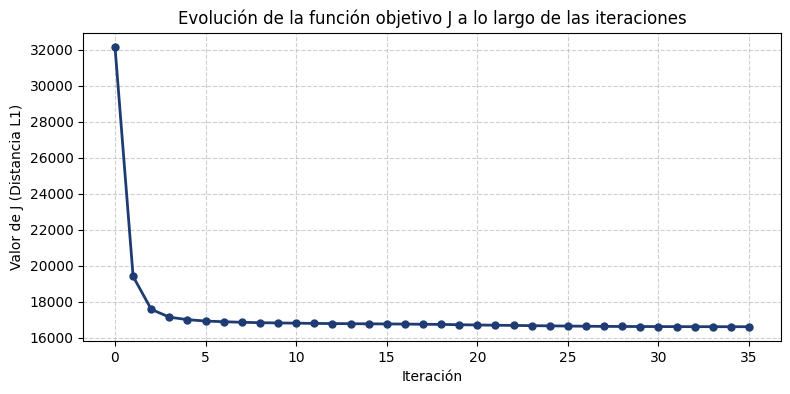

In [10]:
# TODO (c)
modelo = MiVariante(n_clusters=6)
modelo.fit(X1)

# Comprobación de predict
predicciones = modelo.predict(X1)
coinciden_predict = np.array_equal(predicciones, modelo.labels_)
print(f"¿predict(X1) coincide exactamente con labels_?: {coinciden_predict}")

# Dibujar la evolución del objetivo
plt.figure(figsize=(9, 4))
plt.plot(modelo.historial_j, marker='o', color='#1f3b73', lw=2, markersize=5)
plt.title("Evolución de la función objetivo J a lo largo de las iteraciones")
plt.xlabel("Iteración")
plt.ylabel("Valor de J (Distancia L1)")
plt.grid(True, ls="--", alpha=0.6)
plt.show()

In [11]:
# Datos de prueba exactos del ejemplo a mano
X_prueba = np.array([
    [0.1, 0.1, 0.1],
    [0.2, 0.2, 0.2],
    [0.8, 0.8, 0.8],
    [0.9, 0.9, 0.9]
])

# Ejecución de la variante
modelo_prueba = MiVariante(n_clusters=2, pesos=(1/3, 1/3, 1/3))
modelo_prueba.fit(X_prueba)

# Comprobaciones de las propiedades resueltas a mano
print("Etiquetas esperadas: [0 0 1 1]")
print(f"Etiquetas obtenidas: {modelo_prueba.labels_}")

print("\nCentros esperados: \n[[0.15 0.15 0.15]\n [0.85 0.85 0.85]]")
print(f"Centros obtenidos: \n{modelo_prueba.cluster_centers_}")

print("\nValor de J esperado: 0.2")
print(f"Valor de J obtenido (último de historial): {modelo_prueba.historial_j[-1]:.2f}")

assert np.array_equal(modelo_prueba.labels_, [0, 0, 1, 1]), "Las etiquetas no coinciden."
assert np.allclose(modelo_prueba.cluster_centers_, [[0.15, 0.15, 0.15], [0.85, 0.85, 0.85]]), "Los centros no coinciden."
assert np.isclose(modelo_prueba.historial_j[-1], 0.2), "El valor objetivo J no coincide."
print("\n¡El cálculo a mano coincide exactamente con la implementación!")

Etiquetas esperadas: [0 0 1 1]
Etiquetas obtenidas: [0 0 1 1]

Centros esperados: 
[[0.15 0.15 0.15]
 [0.85 0.85 0.85]]
Centros obtenidos: 
[[0.15 0.15 0.15]
 [0.85 0.85 0.85]]

Valor de J esperado: 0.2
Valor de J obtenido (último de historial): 0.20

¡El cálculo a mano coincide exactamente con la implementación!


### 1(d) — la paleta de tres cuadros, con vuestra variante y con `KMeans`

**TODO.** Para cada cuadro de `CUADROS_EJ1` y para $K \in \{3, 6, 12\}$, ajustad **vuestra
variante** sobre todos los píxeles, sustituid cada píxel por el centro (o representante) de su
grupo y mostrad el original y las tres versiones con su paleta debajo (`mostrar_paleta`). Ajustad
también `KMeans(n_clusters=K, n_init=1, random_state=SEED)` y comparad en una tabla el objetivo
$J$ de los dos y el tiempo de ajuste. Responded a las preguntas del enunciado.

In [17]:
K_PALETA = [3, 6, 12]
CUADROS_EJ1 
fila = cuadros.set_index("row_id").loc[CUADROS_EJ1[0]]
img1_original = cargar_imagen(fila["fichero"])
X1 = a_pixeles(img1_original) #Pixeles cuadro 1
fila2 = cuadros.set_index("row_id").loc[CUADROS_EJ1[1]]
img2_original = cargar_imagen(fila2["fichero"])
X2 = a_pixeles(img2_original) #Pixeles cuadro 2
fila3 = cuadros.set_index("row_id").loc[CUADROS_EJ1[2]]
img3_original = cargar_imagen(fila3["fichero"])
X3 = a_pixeles(img3_original) #Pixeles cuadro 3
#Modelo para el cuadro 1 con los diferentes k
lista_modelos_cuadro1 = []
lista_modelos_cuadro2 = []
lista_modelos_cuadro3 = []
for k in K_PALETA:
    modelo1 = MiVariante(n_clusters=k)
    modelo1.fit(X1)
    lista_modelos_cuadro1.append(modelo1)
    modelo2 = MiVariante(n_clusters=k)
    modelo2.fit(X2)
    lista_modelos_cuadro2.append(modelo2)
    modelo3 = MiVariante(n_clusters=k)
    modelo3.fit(X3)
    lista_modelos_cuadro3.append(modelo3)

Sustituir cada pixel por el centroide de su respectivo grupo.
En labels sustituyes cada pixel por el grupo al que pertenece, y te da un array donde en vez de aparecer 
píxeles aparecen los grupos a los que pertenecen. Tras eso, en X1_sustituido, sustituyes cada grupo 
por el centroide correspondiente, y te da un array donde en vez de aparecer los grupos aparecen los centroides.

In [18]:
X1
print(lista_modelos_cuadro1[0].cluster_centers_)
lista_modelos_cuadro1[0].labels_
X1_sustituido = lista_modelos_cuadro1[0].cluster_centers_[lista_modelos_cuadro1[0].labels_] 

[[0.86666667 0.74901961 0.64313725]
 [0.22745098 0.22352941 0.21960784]
 [0.7254902  0.36470588 0.23921569]]


Visualizar imagen original y versiones K = 3, K = 6 y K = 12.

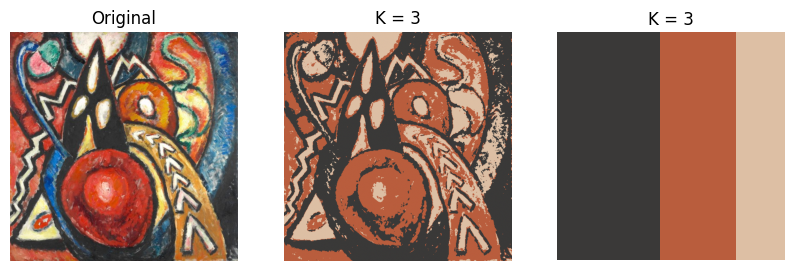

In [47]:
#Mostrar la paleta de colores del cuadro 1 con k=3
img1_original




ModeloK3 = lista_modelos_cuadro1[0]
RecoloreadoK3 = ModeloK3.cluster_centers_[ModeloK3.labels_].reshape(img1_original.shape)

fig, axs = plt.subplots(1, 3, figsize=(10, 5))
axs[0].imshow(img1_original);        axs[0].set_title("Original"); axs[0].axis("off")
axs[1].imshow(RecoloreadoK3); axs[1].set_title("K = 3");    axs[1].axis("off")
axs[2].imshow(RecoloreadoK3); axs[2].set_title("K = 3");    axs[2].axis("off")


mostrar_paleta(axs[2], ModeloK3.cluster_centers_, np.bincount(ModeloK3.labels_))
plt.show()

### 1(d) — lectura

**TODO.** Responded a las preguntas del enunciado: qué se conserva y qué se pierde al bajar $K$;
por qué los colores de la paleta parecen más apagados; qué les pasa a los colores llamativos de poca
superficie; y qué hace **vuestra** variante distinto de `KMeans`, con los números de la tabla.

---
## Ejercicio 2 — De cuadros a vectores: un diccionario común de colores (1.5)

Para agrupar **cuadros** hace falta describir cada uno con el mismo vector. Aquí $K_{\mathrm{dic}}$
es el tamaño del diccionario, fijado por el curso en `K_DIC = 24`. El diccionario se construye con
`sklearn.cluster.KMeans`.

### 2(a) — por qué no se comparan paletas directamente

**TODO.** Dos o tres frases.

### 2(b) — el diccionario

**TODO.** Tomad `PIX_POR_CUADRO` píxeles de cada cuadro, sin reemplazo, con un único
`rng = np.random.default_rng(SEED)` y recorriendo los cuadros en el orden de `cuadros.csv`.
Ajustad `KMeans(n_clusters=K_DIC, n_init=1, random_state=SEED)` sobre todos ellos juntos y
mostrad los 24 colores del diccionario.

In [ ]:
imagenes = [cargar_imagen(f) for f in cuadros["fichero"]]
pixeles = [a_pixeles(im) for im in imagenes]
# TODO (b)

### 2(c) — la tabla de histogramas

**TODO.** Asignad **todos** los píxeles de cada cuadro al color más cercano del diccionario y
construid la tabla `H` ($n \times K_{\mathrm{dic}}$) con la proporción de cada color en cada cuadro.
Comprobad que cada fila suma 1 y mostrad, para dos cuadros que elijáis, su fila de `H` como un
diagrama de barras con los colores del diccionario.

In [ ]:
# TODO (c)
H = None

### 2(d) — qué describe `H`, y la decisión de escala

**TODO.** ¿Qué describe una fila de `H` y qué ignora? ¿Vais a escalar `H` antes de agrupar?
Declarad la decisión, nombradla y argumentadla: las dos respuestas son defendibles, pero solo una
declarada y argumentada puntúa.

---
## Ejercicio 3 — $K$-means y vuestra variante sobre los cuadros (2.0)

Aquí $K$ es el **número de grupos de cuadros**. La entrada es la tabla `H` del Ejercicio 2.
**El apartado (d) no está aquí**: necesita los metadatos y pertenece a la revelación.

### 3(a) — la rejilla

**TODO.** Para $K \in \{3, \dots, 8\}$: `KMeans` una vez con **cada** semilla de `P1_SEEDS` y
`n_init=1`, y **vuestra variante** (con las tres semillas si es aleatoria; una vez si es
determinista). Para cada ejecución: $J$, la silueta y los tamaños de grupo; para `KMeans`, además,
la **media** de $J$ en las tres semillas y su dispersión.

In [ ]:
from sklearn.metrics import silhouette_score

K_GRID = list(range(3, 9))
# TODO (a)

### 3(a) — lectura

**TODO.** ¿Qué muestra la tabla? ¿Por qué informar del **mejor** de los tres reinicios de `KMeans`
hablaría de vuestra inicialización más afortunada y no de $K$? ¿Cómo se compara vuestra variante?

### Antes de congelar: las reglas

Tres preguntas distintas, que no deben mezclarse:

1. **¿Qué $K$?** A partir de la evidencia **no supervisada**. $J$ baja con $K$ por construcción, así
   que «$J$ es mínimo en $K = 8$» no es un argumento.
2. **¿Qué algoritmo?** `KMeans` o vuestra variante, con una regla no supervisada declarada.
3. **¿Qué ejecución?** Solo **después** de fijar $K$ y algoritmo, si hay varias (por ejemplo, la de
   menor $J$ **con el $K$ ya fijado**).

**TODO — escribid aquí las reglas**, y aplicadlas en la celda siguiente.

In [ ]:
# TODO (b) Aplicad las reglas: fijad K, el algoritmo y UNA partición. Guardad sus etiquetas:
#          la rejilla de miniaturas y la revelación deben usarla a ella.
K_REF = None
ALGORITMO_REF = None
SEMILLA_REF = None
grupos_km = None

### 3(b) — los grupos, vistos

**TODO.** Mostrad la rejilla de miniaturas de vuestra partición con `rejilla_miniaturas` y
describid cada grupo **en términos de color y de luz**: todavía no sabéis quién pintó cada cuadro,
y vuestro argumento no puede apoyarse en reconocerlo.

In [ ]:
# TODO (b) rejilla_miniaturas(cuadros["fichero"], grupos_km)

## DECISIÓN CONGELADA — K-MEANS

**TODO — 3(c). Este encabezado es uno de los dos que comprueba el sello. No lo cambiéis.**

Rellenadlo **antes** que nada de lo que sigue y antes de que ninguna celda lea los metadatos. Lo
que se congela es **una** partición.

| Campo | Valor |
|---|---|
| $K$ | *TODO* |
| Algoritmo (`KMeans` o vuestra variante) | *TODO* |
| Semilla, si procede | *TODO* |
| Escalado de `H` | *TODO* |
| Reglas que eligieron $K$, algoritmo y ejecución | *TODO* |

**Argumento no supervisado.** *TODO. Si parte de vuestra evidencia apunta en otra dirección,
decidlo: una elección congelada con una limitación reconocida puntúa mejor que una presentada
como indiscutible.*

In [ ]:
# Congelad la tabla anterior en código, para que nada de lo que sigue pueda apartarse de ella.
CONGELADO_KMEANS = dict(K=K_REF, algoritmo=ALGORITMO_REF, semilla=SEMILLA_REF)
print("CONGELADO_KMEANS:", CONGELADO_KMEANS)

---
## Ejercicio 4 — Agrupamiento jerárquico de los cuadros (2.0)

La misma tabla `H` y el mismo sello: **los apartados (a) a (c) no usan metadatos**. Aquí $K$ es
también el número de grupos.

### 4(a) — los cuatro enlaces

**TODO.** Agrupamiento aglomerativo con `ward`, `complete`, `average` y `single`. Indicad la
restricción de métrica de `ward` y mostrad qué ocurre si se le pide otra.

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage as scipy_linkage

ENLACES = ["ward", "complete", "average", "single"]
# TODO (a)

### 4(b) — dos criterios, declarados antes de aplicarlos

1. **Dentro de cada enlace, ¿qué $K$?** Cada enlace es una jerarquía distinta: **cada enlace
   tiene su propio $K$**.
2. **Entre enlaces, ¿cuál preferís?** Una regla que pueda elegir uno, solo con evidencia no
   supervisada. «El que se ve mejor» no es una regla.

**TODO — escribid aquí las dos reglas** y aplicadlas en la celda siguiente.

In [ ]:
# TODO (b) Regla 1 en CADA enlace -> elegidos[enlace] = K. Regla 2 -> un enlace preferido.
elegidos = {}
ENLACE_REF = None

### 4(c) — un dendrograma

**TODO.** El dendrograma del enlace **preferido**, cortado en **su** $K$, con
`dendrograma_con_miniaturas`. Leedlo: ¿qué fusiones son tempranas y baratas, y cuál es tan cara
que vuestra regla cortó por debajo?

In [ ]:
# TODO (c) dendrograma_con_miniaturas(scipy_linkage(H, method=ENLACE_REF), cuadros["fichero"], K=elegidos[ENLACE_REF])

## DECISIÓN CONGELADA — AGLOMERATIVO

**TODO. El segundo encabezado que comprueba el sello. No lo cambiéis.**

| Enlace | $K$ congelado | Por qué la regla 1 llegó ahí |
|---|---|---|
| `ward` | *TODO* | *TODO* |
| `complete` | *TODO* | *TODO* |
| `average` | *TODO* | *TODO* |
| `single` | *TODO* | *TODO* |

**Enlace preferido (regla 2):** *TODO*, y por qué.

In [ ]:
CONGELADO_AGLO = dict(elegidos)       # enlace -> su K congelado
ENLACE_PREFERIDO = ENLACE_REF
print("CONGELADO_AGLO  :", CONGELADO_AGLO)
print("ENLACE_PREFERIDO:", ENLACE_PREFERIDO)

In [ ]:
# TODO Registrad los tamaños de grupo OBSERVADOS en cada enlace con su K congelado, antes de la
#      revelación: el apartado (e) los necesita.

---
## REVELACIÓN — VALIDACIÓN EXTERNA

**Este es el primer punto en el que podéis tocar los metadatos.** Están en `Datos/metadatos.csv`:
autor, época, año, técnica, título y la referencia del museo. Se alinean por **`row_id`**.

Las dos configuraciones de arriba están congeladas y nada de lo que sigue puede cambiarlas.
Recalcular índices para varios $K$, semillas, algoritmos o enlaces y presentar el mejor es una
penalización automática.

In [ ]:
# Se abre AQUÍ, dentro de la revelación, y en ningún sitio antes.
METADATOS_FILE = os.path.join(DATOS, "metadatos.csv")


def cargar_metadatos(cuadros, path=None):
    """metadatos.csv: row_id, autor, epoca, anio, tecnica, titulo, tecnica_original, aic_id.
    Se alinea por row_id con la tabla de cuadros, nunca por posición."""
    meta = pd.read_csv(path or METADATOS_FILE)
    m = cuadros[["row_id"]].merge(meta, on="row_id", how="left", validate="1:1")
    assert m["autor"].notna().all(), "hay un cuadro sin metadatos"
    assert (m["row_id"].to_numpy() == cuadros["row_id"].to_numpy()).all()
    return m

In [ ]:
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score

# TODO Cargad los metadatos por primera vez con cargar_metadatos(cuadros).
meta = None
y_autor = None
y_epoca = None

### 3(d) — validación externa de la partición congelada

**TODO.** Índice de Rand ajustado (ARI) e información mutua ajustada (AMI) de la partición
congelada **frente al autor y frente a la época**, y la tabla de contingencia grupo × autor.
Volved a mostrar la rejilla de miniaturas, ahora con el autor de cada cuadro a la vista
(argumento `rotulos` de `rejilla_miniaturas`). Después, la pregunta de fondo: **¿qué ha agrupado
realmente el algoritmo?**

In [ ]:
# TODO 3(d) solo para la partición CONGELADA

### 4(d) — validación externa de cada enlace congelado

**TODO.** Los mismos índices para **cada** enlace con **su** $K$ congelado. Indicad el $K$ en cada
fila y marcad el enlace preferido. Después, la comparación: ¿coinciden el enlace con **mejor**
acuerdo con el autor y el que preferisteis **sin** metadatos? Si no coinciden, decidlo sin rodeos.

In [ ]:
# TODO 4(d) AgglomerativeClustering(n_clusters=CONGELADO_AGLO[lk], linkage=lk) para cada lk

### 4(e) — comparación de los cuatro enlaces

**TODO.** Con los tamaños de grupo que registrasteis **antes** de la revelación, comparad lo que
hicieron los cuatro enlaces con estos datos y explicad cada uno a partir de lo que mide entre dos
grupos. Comprobad si `single` muestra **encadenamiento**; si no lo muestra, decidlo.

---
## Ejercicio 5 — PCA: el mapa de los cuadros (1.5)

PCA sobre la tabla `H`, centrada y **con la misma decisión de escala del Ejercicio 2(d)**. Aquí
$r$ es el número de componentes.

**TODO (a).** Ajustad `PCA` sobre `H` e informad de la razón de varianza explicada de las
primeras componentes, de la acumulada y de cuántas componentes hacen falta para el 90 %.

In [ ]:
from sklearn.decomposition import PCA
# TODO (a)

**TODO (b).** El mapa de los cuadros en CP1–CP2 con `mapa_con_miniaturas`, y las **cargas** de
CP1 y CP2 como un diagrama de barras con los colores del diccionario.

In [ ]:
# TODO (b)

**TODO (c).** Interpretad CP1 y CP2 **con palabras de color**, a partir de las cargas. Después
coloread el marco de cada miniatura por autor (ya revelado) y relacionad las tres cosas:
componentes, grupos de vuestra partición congelada y autores.

In [ ]:
# TODO (c)

---
## Antes de entregar

1. **Reiniciad el núcleo y ejecutad todas las celdas de arriba abajo, en una sola pasada.**
   Guardad con las salidas.
2. Ejecutad la comprobación del sello sobre el fichero guardado.
3. Renombrad el fichero como `p1_grupo<N>.ipynb`, con vuestro número de grupo.
4. Entregad el cuaderno y `USO_IA.md`.

In [ ]:
# Comprobación del sello. Apuntadla al fichero GUARDADO.
# check_seal(f"p1_grupo{GRUPO}.ipynb")